# Pattern Recognition and Machine Learning (EE602L)
## Lab 2 — Regression: Parameter Estimation and Regularization

**Name:** _<your name>_  **Roll number:** _<your roll number>_  **Date:** August 2026

**Dataset:** `housing.csv` — California Housing (1990 U.S. Census), 20,640 districts.

**Contents**
1. Data preparation — inspection, cleaning, visualisation, manual 70:15:15 split, train-only scaling
2. **Part (a)** — closed-form MMSE estimation vs. gradient descent (MSE cost and MAE cost)
3. **Part (b)** — plain Linear Regression vs. Ridge vs. Lasso

Everything except `sklearn.linear_model.Lasso` is implemented from scratch with NumPy.
No `sklearn.model_selection` is used anywhere: the split is written by hand.

In [2]:
# ── Imports and global configuration ──────────────────────────────────────────
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso          # only estimator imported from sklearn

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.width", 140, "display.max_columns", 30)

SEED = 42                      # single seed => the whole notebook is reproducible
np.random.seed(SEED)
URL = ("https://raw.githubusercontent.com/ageron/handson-ml2/"
       "master/datasets/housing/housing.csv")

---
# 1. Data preparation

## 1.1 Load and inspect

In [3]:
df = pd.read_csv(URL)                      # in Colab this downloads directly
print("shape:", df.shape)
df.head()

shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
# Column types and summary statistics
print(df.dtypes, "\n")
df.describe().T.round(2)

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object 



,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


In [5]:
# Missing values, duplicates, and the single categorical column
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nocean_proximity value counts:")
print(df["ocean_proximity"].value_counts())

Missing values per column:
total_bedrooms    207
dtype: int64

Exact duplicate rows: 0

ocean_proximity value counts:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


**What the inspection tells us**

* 20,640 rows × 10 columns; 9 numerical + 1 categorical (`ocean_proximity`).
* `total_bedrooms` has **207 missing values** (1.0 %). Every other column is complete.
* There are **no exact duplicate rows**.
* Three columns are *censored* by the census methodology — they pile up at an artificial
  maximum: `median_house_value` at 500,001, `median_income` at 15.0001 and
  `housing_median_age` at 52.
* `ocean_proximity = ISLAND` occurs in only **5** of 20,640 records.
* The four "district size" columns (`total_rooms`, `total_bedrooms`, `population`,
  `households`) are strongly right-skewed — maxima are ~15–30× their medians.

## 1.2 Cleaning decisions

Two kinds of decisions are made, and they are kept strictly separate:

**(i) Data-validity removals** (not outlier treatment — these rows are *invalid targets*,
and the rule uses no estimated statistic, so it may be applied before splitting):

| Removed | Rows | Reason |
|---|---|---|
| `median_house_value` ≥ 500,000 | 992 | Target is censored at the census cap; the true value is unknown, so a regression on it is fitting an artefact. |
| `ocean_proximity == "ISLAND"` | 5 | A category with 5 records in 20,640 cannot be estimated; its dummy column is near-degenerate and inflates the condition number of *X*. |

**(ii) Outlier criterion — one rule, applied consistently: 1.5 × IQR capping (winsorisation).**
For every heavy-tailed numeric predictor (`total_rooms`, `total_bedrooms`, `population`,
`households`, `median_income`) values outside
$[Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}]$ are **clipped to the boundary, not deleted**.
Capping is preferred to deletion because a genuinely large district is still a valid
observation — only its leverage on a squared-error fit is unreasonable.
`longitude`, `latitude` and `housing_median_age` are bounded, physically meaningful
quantities and are left untouched. The target is never capped.

The bounds are computed on the **training split only** (Section 1.4) and then applied
unchanged to validation and test.

In [6]:
TARGET = "median_house_value"
NUM = ["longitude", "latitude", "housing_median_age", "total_rooms",
       "total_bedrooms", "population", "households", "median_income"]
CAT = "ocean_proximity"
SKEWED = ["total_rooms", "total_bedrooms", "population", "households", "median_income"]

raw = df.copy()                                       # keep a copy for the "before" plot
df = df.drop_duplicates().reset_index(drop=True)

n_censored = int((df[TARGET] >= 500000).sum())
n_island   = int((df[CAT] == "ISLAND").sum())
df = df[df[TARGET] < 500000].reset_index(drop=True)   # censored target
df = df[df[CAT] != "ISLAND"].reset_index(drop=True)   # degenerate category

print(f"removed {n_censored} censored-target rows and {n_island} ISLAND rows")
print("shape after cleaning:", df.shape)
print("target range now:", df[TARGET].min(), "-", df[TARGET].max())

removed 992 censored-target rows and 5 ISLAND rows
shape after cleaning: (19643, 10)
target range now: 14999.0 - 499100.0


## 1.3 Visualising the data before modelling

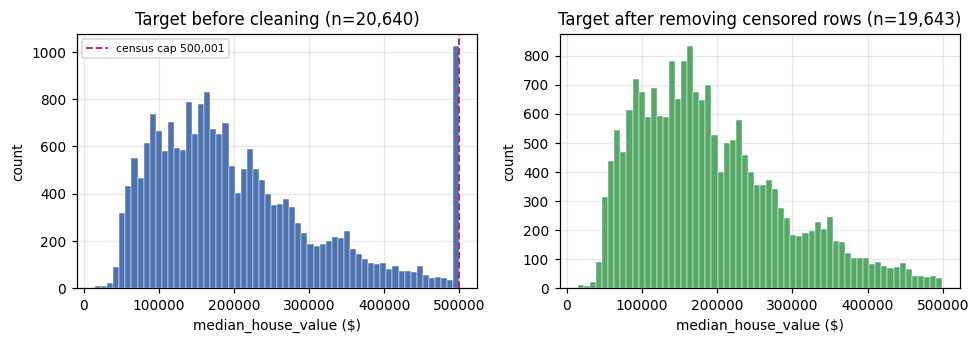

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(raw[TARGET], bins=60, color="#4c72b0", edgecolor="white", linewidth=.3)
ax[0].axvline(500001, color="crimson", ls="--", lw=1.2, label="census cap 500,001")
ax[0].set_title("Target before cleaning (n=20,640)"); ax[0].legend(fontsize=7)
ax[1].hist(df[TARGET], bins=60, color="#55a868", edgecolor="white", linewidth=.3)
ax[1].set_title(f"Target after removing censored rows (n={len(df):,})")
for a in ax: a.set_xlabel("median_house_value ($)"); a.set_ylabel("count")
fig.tight_layout(); plt.show()

The spike of ~1,000 districts at exactly \$500,001 is the census cap. Removing it leaves a
right-skewed but otherwise well-behaved target between \$14,999 and \$499,100.

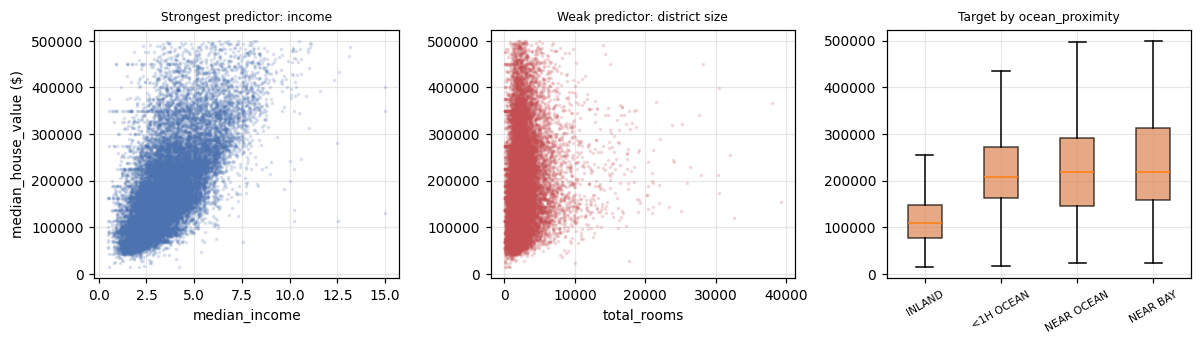

median_house_value    1.000
median_income         0.647
total_rooms           0.145
households            0.096
total_bedrooms        0.075
housing_median_age    0.065
population            0.014
longitude            -0.046
latitude             -0.149
Name: median_house_value, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].scatter(df["median_income"], df[TARGET], s=2, alpha=.15, color="#4c72b0")
ax[0].set_xlabel("median_income"); ax[0].set_ylabel("median_house_value ($)")
ax[0].set_title("Strongest predictor: income", fontsize=8)
ax[1].scatter(df["total_rooms"], df[TARGET], s=2, alpha=.15, color="#c44e52")
ax[1].set_xlabel("total_rooms"); ax[1].set_title("Weak predictor: district size", fontsize=8)
order = df.groupby(CAT)[TARGET].median().sort_values().index
ax[2].boxplot([df.loc[df[CAT] == c, TARGET] for c in order], showfliers=False,
              patch_artist=True, boxprops=dict(facecolor="#dd8452", alpha=.7))
ax[2].set_xticks(range(1, len(order) + 1)); ax[2].set_xticklabels(list(order))
ax[2].tick_params(axis="x", rotation=30, labelsize=7)
ax[2].set_title("Target by ocean_proximity", fontsize=8)
fig.tight_layout(); plt.show()

print(df[NUM + [TARGET]].corr()[TARGET].sort_values(ascending=False).round(3))

`median_income` is by far the strongest linear predictor (r ≈ 0.65). The raw size columns
correlate only weakly with price (r ≈ 0.01–0.18) — they mostly describe how *big* a district
is, not how *expensive* it is. `INLAND` districts are visibly cheaper than coastal ones,
so the categorical column carries real signal.

## 1.4 Manual 70 : 15 : 15 split (NumPy only)

A random permutation of the row indices is sliced into three disjoint blocks. Because the
blocks are slices of one permutation they are disjoint **by construction**; the check below
confirms it empirically.

In [9]:
rng = np.random.default_rng(SEED)
n = len(df)
perm = rng.permutation(n)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
idx_tr, idx_va, idx_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]

train = df.iloc[idx_tr].copy()
val   = df.iloc[idx_va].copy()
test  = df.iloc[idx_te].copy()

print(f"train {len(train):>6,}  ({len(train)/n:.2%})")
print(f"val   {len(val):>6,}  ({len(val)/n:.2%})")
print(f"test  {len(test):>6,}  ({len(test)/n:.2%})")
print(f"total {len(train)+len(val)+len(test):>6,}  (dataset {n:,})")

s_tr, s_va, s_te = set(idx_tr), set(idx_va), set(idx_te)
print("\noverlap train∩val :", len(s_tr & s_va))
print("overlap train∩test:", len(s_tr & s_te))
print("overlap val∩test  :", len(s_va & s_te))
print("union covers every row:", len(s_tr | s_va | s_te) == n)

train 13,750  (70.00%)
val    2,946  (15.00%)
test   2,947  (15.00%)
total 19,643  (dataset 19,643)

overlap train∩val : 0
overlap train∩test: 0
overlap val∩test  : 0
union covers every row: True


## 1.5 Imputation, capping, encoding and scaling — all fitted on the training set only

Every statistic used to transform the data (the imputation median, the IQR bounds, the
standardisation mean/std, the set of categories) is computed **from `train` alone** and then
applied to `val` and `test`. This is what keeps the validation and test estimates honest.

In [10]:
# ---- statistics estimated on the TRAINING split only -------------------------
med_bed = train["total_bedrooms"].median()
bounds  = {}
for c in SKEWED:
    q1, q3 = train[c].quantile(0.25), train[c].quantile(0.75)
    iqr = q3 - q1
    bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print(f"total_bedrooms imputation value (train median) = {med_bed:.1f}\n")
print(pd.DataFrame(bounds, index=["lower", "upper"]).T.round(2))

pre_cap = train[SKEWED].copy()
pre_cap["total_bedrooms"] = pre_cap["total_bedrooms"].fillna(med_bed)

def prepare(d):
    """Impute with the training median, then winsorise with the training IQR bounds."""
    d = d.copy()
    d["total_bedrooms"] = d["total_bedrooms"].fillna(med_bed)
    for c in SKEWED:
        lo, hi = bounds[c]
        d[c] = d[c].clip(lo, hi)
    return d

n_capped = pd.DataFrame({name: {c: int(((d[c] < bounds[c][0]) | (d[c] > bounds[c][1])).sum())
                                for c in SKEWED}
                         for name, d in [("train", train), ("val", val), ("test", test)]})
n_imputed = {name: int(d["total_bedrooms"].isna().sum())
             for name, d in [("train", train), ("val", val), ("test", test)]}

train, val, test = prepare(train), prepare(val), prepare(test)
print("\nvalues imputed:", n_imputed)
print("\nvalues capped:"); print(n_capped)

total_bedrooms imputation value (train median) = 438.0

                  lower    upper
total_rooms    -1069.62  5649.38
total_bedrooms  -230.50  1181.50
population      -639.00  3193.00
households      -207.00  1097.00
median_income     -0.53     7.63

values imputed: {'train': 146, 'val': 28, 'test': 26}

values capped:
                train  val  test
total_rooms       872  192   183
total_bedrooms    839  182   172
population        768  175   160
households        809  183   161
median_income     272   55    49


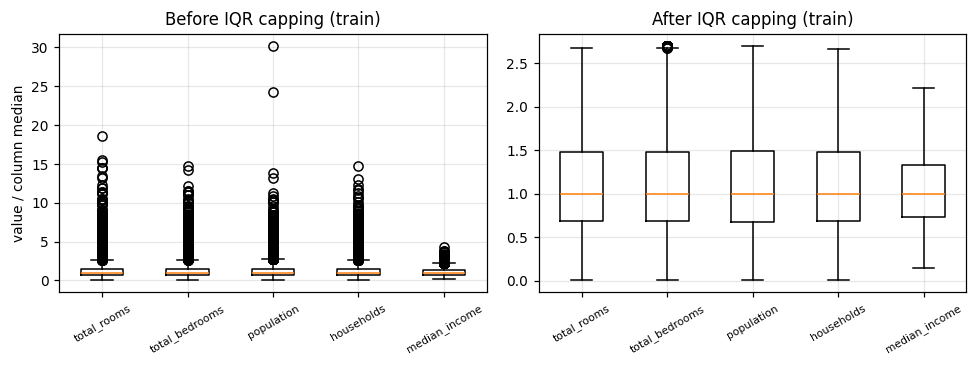

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].boxplot([pre_cap[c] / pre_cap[c].median() for c in SKEWED])
ax[0].set_xticks(range(1, len(SKEWED) + 1)); ax[0].set_xticklabels(SKEWED)
ax[0].set_title("Before IQR capping (train)"); ax[0].set_ylabel("value / column median")
ax[1].boxplot([train[c] / pre_cap[c].median() for c in SKEWED])
ax[1].set_xticks(range(1, len(SKEWED) + 1)); ax[1].set_xticklabels(SKEWED)
ax[1].set_title("After IQR capping (train)")
for a in ax: a.tick_params(axis="x", rotation=30, labelsize=7)
fig.tight_layout(); plt.show()

In [12]:
# ---- one-hot encoding: categories fixed from train, first level dropped ------
cats    = sorted(train[CAT].unique())
BASE    = cats[0]                      # reference level absorbed by the intercept
DUMMIES = [f"ocean_{c}" for c in cats[1:]]
print("categories:", cats, "| base level:", BASE)

def design(d):
    Xn = d[NUM].to_numpy(float)
    Xd = np.column_stack([(d[CAT] == c).to_numpy(float) for c in cats[1:]])
    return np.hstack([Xn, Xd]), d[TARGET].to_numpy(float)

Xtr_raw, ytr = design(train)
Xva_raw, yva = design(val)
Xte_raw, yte = design(test)

# ---- standardise the numerical block with TRAIN mean / std ------------------
mu = Xtr_raw[:, :len(NUM)].mean(0)
sd = Xtr_raw[:, :len(NUM)].std(0, ddof=0)

def scale(X):
    X = X.copy(); X[:, :len(NUM)] = (X[:, :len(NUM)] - mu) / sd; return X

Xtr_s, Xva_s, Xte_s = scale(Xtr_raw), scale(Xva_raw), scale(Xte_raw)

# 0/1 dummies are left unscaled so each coefficient reads as "$ difference vs <1H OCEAN"
FEATS = NUM + DUMMIES
add_intercept = lambda X: np.hstack([np.ones((len(X), 1)), X])
Xtr, Xva, Xte = add_intercept(Xtr_s), add_intercept(Xva_s), add_intercept(Xte_s)
p = Xtr.shape[1] - 1                    # predictors excluding the intercept

print(f"\ndesign matrices  train {Xtr.shape}  val {Xva.shape}  test {Xte.shape}")
print(f"p = {p} predictors + 1 intercept")
print("train numeric means ≈ 0 :", np.abs(Xtr_s[:, :len(NUM)].mean(0)).max() < 1e-12)
print("train numeric stds  = 1 :", np.allclose(Xtr_s[:, :len(NUM)].std(0), 1))

categories: ['<1H OCEAN', 'INLAND', 'NEAR BAY', 'NEAR OCEAN'] | base level: <1H OCEAN

design matrices  train (13750, 12)  val (2946, 12)  test (2947, 12)
p = 11 predictors + 1 intercept
train numeric means ≈ 0 : True
train numeric stds  = 1 : True


---
# 2. Part (a) — MMSE parameter estimation vs. gradient descent

## 2.1 Metric helpers

In [13]:
def metrics(y, yh, p):
    """MSE, RMSE, MAE, R^2 and adjusted R^2 for predictions yh of y."""
    e   = y - yh
    mse = float(np.mean(e ** 2))
    r2  = float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2))
    n_  = len(y)
    return {"MSE": mse, "RMSE": float(np.sqrt(mse)), "MAE": float(np.mean(np.abs(e))),
            "R2": r2, "R2_adj": float(1 - (1 - r2) * (n_ - 1) / (n_ - p - 1))}

def predict(X, theta):
    """y_hat = X theta  (X already contains the intercept column)."""
    return X @ theta

def table(d, name="model"):
    return pd.DataFrame(d).T.rename_axis(name)

## 2.2 Closed-form MMSE solution  $\theta = (X^TX)^{-1}X^Ty$

`np.linalg.pinv` is used instead of an explicit inverse. The Moore–Penrose pseudo-inverse is
computed from the SVD of $X$, so it works on the singular values of $X$ (condition number
$\kappa$) rather than on those of $X^TX$ (condition number $\kappa^2$) — roughly **half the
digits are lost**. It also returns the minimum-norm solution instead of raising an error if
$X^TX$ is singular, which happens whenever two features are exactly collinear (e.g. if all
dummy levels were kept). Here $X$ is well conditioned, so both routes agree to ~1e-9 — the
pseudo-inverse costs nothing and removes the failure mode.

In [14]:
XtX = Xtr.T @ Xtr
print(f"cond(X)   with raw features        = {np.linalg.cond(add_intercept(Xtr_raw)):,.0f}")
print(f"cond(X)   with standardised features = {np.linalg.cond(Xtr):.2f}")
print(f"cond(X^T X)                          = {np.linalg.cond(XtX):.2f}   (= cond(X)^2)")
print(f"rank(X) = {np.linalg.matrix_rank(Xtr)} of {Xtr.shape[1]} columns -> full rank")

t0 = time.perf_counter()
theta_mmse = np.linalg.pinv(Xtr) @ ytr            # SVD-based, numerically safer
t_mmse = time.perf_counter() - t0

theta_inv = np.linalg.solve(XtX, Xtr.T @ ytr)     # naive normal equations
print(f"\n||theta_pinv - theta_normal-equations||_2 = {np.linalg.norm(theta_mmse - theta_inv):.3e}")
print(f"closed-form fit time = {t_mmse*1000:.2f} ms")

cond(X)   with raw features        = 598,908
cond(X)   with standardised features = 14.01
cond(X^T X)                          = 196.32   (= cond(X)^2)
rank(X) = 12 of 12 columns -> full rank

||theta_pinv - theta_normal-equations||_2 = 1.082e-09
closed-form fit time = 8.06 ms


In [15]:
coef = pd.DataFrame({"feature": ["intercept"] + FEATS, "coefficient ($)": theta_mmse})
coef["|coef|"] = coef["coefficient ($)"].abs()
display(coef.round(1))

res_a = {"MMSE  train": metrics(ytr, predict(Xtr, theta_mmse), p),
         "MMSE  val":   metrics(yva, predict(Xva, theta_mmse), p)}
table(res_a).round(4)

,feature,coefficient ($),|coef|
0,intercept,205652.2,205652.2
1,longitude,-46367.1,46367.1
2,latitude,-46261.0,46261.0
3,housing_median_age,11135.9,11135.9
4,total_rooms,-18511.0,18511.0
5,total_bedrooms,33886.8,33886.8
6,population,-43222.6,43222.6
7,households,32705.9,32705.9
8,median_income,61743.2,61743.2
9,ocean_INLAND,-38300.0,38300.0


,MSE,RMSE,MAE,R2,R2_adj
model,,,,,
MMSE train,3.454132e+09,58771.8638,43616.7676,0.6317,0.6314
MMSE val,3.468964e+09,58897.9078,43890.1403,0.6482,0.6469


Coefficients are in **dollars per one standard deviation** of the (standardised) feature; the
dummies are in dollars relative to the `<1H OCEAN` reference level. `median_income` dominates
(+\$61.7k per SD). Note the physically odd signs inside the size group — `total_rooms` is
*negative* while `households` and `total_bedrooms` are strongly positive. That is the first
symptom of the multicollinearity investigated in Part (b).

## 2.3 Gradient descent on the MSE cost

$$J(\theta)=\tfrac1n\sum_i (y_i-\hat y_i)^2,\qquad
\nabla_\theta J(\theta)=-\tfrac2n X^T(y-X\theta),\qquad
\theta \leftarrow \theta-\alpha\nabla_\theta J(\theta)$$

The same routine also implements the MAE cost of Section 2.4, selected by the `loss` argument.

In [16]:
def gradient_descent(X, y, lr, n_iters, loss="mse", decay=False, tol=1e-9):
    """Batch (sub)gradient descent started from theta = 0.

    loss='mse' : exact gradient  -2/n X^T (y - X theta)
    loss='mae' : subgradient     -1/n X^T sign(y - X theta), with sign(0)=0,
                 a valid element of the subdifferential [-1, 1] at y = y_hat.
    decay=True : step alpha_t = lr / sqrt(1+t), required for subgradient descent to
                 converge (a constant step only reaches an O(alpha) neighbourhood).
    Returns (theta, cost history, iterations used, diverged flag).
    """
    n_, d = X.shape
    theta = np.zeros(d)
    hist  = np.empty(n_iters)
    stop, diverged = n_iters, False
    for t in range(n_iters):
        r = y - X @ theta                            # residuals
        if loss == "mse":
            hist[t] = np.mean(r ** 2)
            grad = -(2.0 / n_) * (X.T @ r)
        else:
            hist[t] = np.mean(np.abs(r))
            grad = -(1.0 / n_) * (X.T @ np.sign(r))
        if not np.isfinite(hist[t]) or hist[t] > 10 * hist[0]:
            hist[t:] = np.nan; stop, diverged = t, True; break
        step  = lr / np.sqrt(1.0 + t) if decay else lr
        theta = theta - step * grad
        if t > 0 and abs(hist[t-1] - hist[t]) / max(hist[t-1], 1e-12) < tol:
            hist[t+1:] = hist[t]; stop = t + 1; break
    return theta, hist, stop, diverged

In [17]:
N_IT = 2000
LRS  = [1e-4, 1e-3, 1e-2, 1e-1, 3e-1]
runs = {}
for lr in LRS:
    th, hist, stop, dv = gradient_descent(Xtr, ytr, lr, N_IT, "mse")
    runs[lr] = dict(theta=th, hist=hist, stop=stop, diverged=dv,
                    train=None if dv else metrics(ytr, predict(Xtr, th), p),
                    val=None if dv else metrics(yva, predict(Xva, th), p))

gd_tab = pd.DataFrame([{"learning rate": lr,
                        "iterations": runs[lr]["stop"],
                        "final train MSE": np.nan if runs[lr]["diverged"] else runs[lr]["train"]["MSE"],
                        "validation MSE":  np.nan if runs[lr]["diverged"] else runs[lr]["val"]["MSE"],
                        "validation R2":   np.nan if runs[lr]["diverged"] else runs[lr]["val"]["R2"],
                        "status": "DIVERGED" if runs[lr]["diverged"] else "converged"}
                       for lr in LRS]).set_index("learning rate")
display(gd_tab)

best_lr = min([lr for lr in LRS if not runs[lr]["diverged"]],
              key=lambda lr: runs[lr]["val"]["MSE"])
print("best learning rate by validation MSE:", best_lr)

,iterations,final train MSE,validation MSE,validation R2,status
learning rate,,,,,
0.0001,2000,2.255563e+10,2.329772e+10,-1.362828,converged
0.0010,2000,4.171264e+09,4.165951e+09,0.577494,converged
0.0100,2000,3.461656e+09,3.476692e+09,0.647398,converged
0.1000,1111,3.454132e+09,3.469004e+09,0.648178,converged
0.3000,15,NaN,NaN,NaN,DIVERGED


best learning rate by validation MSE: 0.1


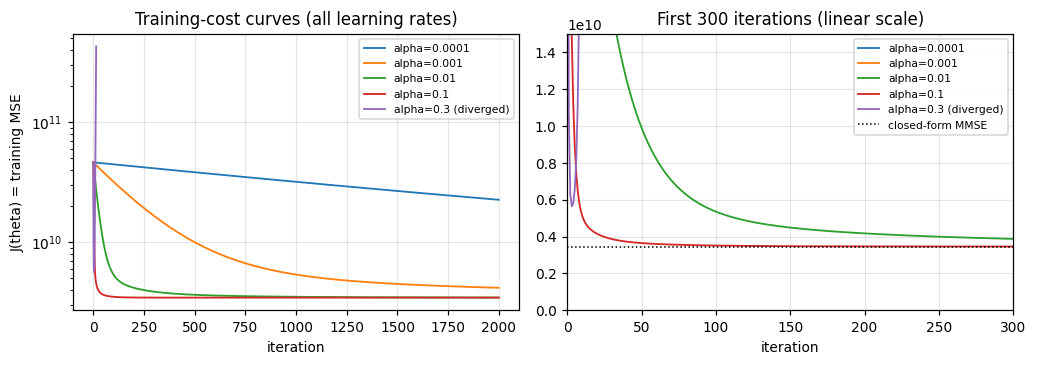

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for lr in LRS:
    lbl = f"alpha={lr}" + (" (diverged)" if runs[lr]["diverged"] else "")
    ax[0].plot(runs[lr]["hist"], lw=1.2, label=lbl)
    ax[1].plot(runs[lr]["hist"], lw=1.2, label=lbl)
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration")
ax[0].set_ylabel("J(theta) = training MSE")
ax[0].set_title("Training-cost curves (all learning rates)"); ax[0].legend(fontsize=7)
ax[1].set_xlim(0, 300); ax[1].set_ylim(0, 1.5e10)
ax[1].axhline(metrics(ytr, predict(Xtr, theta_mmse), p)["MSE"], color="k", ls=":", lw=1,
              label="closed-form MMSE")
ax[1].set_xlabel("iteration"); ax[1].set_title("First 300 iterations (linear scale)")
ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

In [19]:
# timed re-run of the single best-learning-rate configuration
t0 = time.perf_counter()
theta_gd, hist_gd, stop_gd, _ = gradient_descent(Xtr, ytr, best_lr, N_IT, "mse")
t_gd = time.perf_counter() - t0

tgt = metrics(ytr, predict(Xtr, theta_mmse), p)["MSE"] * 1.01
print(f"alpha = {best_lr}: stopped after {stop_gd} iterations, {t_gd*1000:.1f} ms")
print(f"iterations to reach within 1% of the closed-form training MSE: "
      f"{int(np.argmax(hist_gd <= tgt)) + 1}")

cmp = pd.DataFrame({"closed-form MMSE": theta_mmse, f"GD (alpha={best_lr})": theta_gd},
                   index=["intercept"] + FEATS)
cmp["difference ($)"] = cmp.iloc[:, 0] - cmp.iloc[:, 1]
display(cmp.round(2))
print(f"||theta_MMSE - theta_GD||_2 excluding intercept = "
      f"{np.linalg.norm(theta_mmse[1:] - theta_gd[1:]):.2f}  "
      f"(relative to ||theta_MMSE||_2 = {np.linalg.norm(theta_mmse[1:]):,.0f})")

alpha = 0.1: stopped after 1111 iterations, 406.1 ms
iterations to reach within 1% of the closed-form training MSE: 124


,closed-form MMSE,GD (alpha=0.1),difference ($)
intercept,205652.17,205666.92,-14.75
longitude,-46367.14,-46288.32,-78.82
latitude,-46260.96,-46176.98,-83.99
housing_median_age,11135.89,11136.63,-0.75
total_rooms,-18511.03,-18513.50,2.46
total_bedrooms,33886.81,33845.91,40.90
population,-43222.55,-43226.63,4.08
households,32705.95,32753.69,-47.74
median_income,61743.23,61744.76,-1.53
ocean_INLAND,-38299.98,-38350.27,50.29


||theta_MMSE - theta_GD||_2 excluding intercept = 141.44  (relative to ||theta_MMSE||_2 = 119,220)


## 2.4 Gradient descent on the MAE cost

$$J(\theta)=\tfrac1n\sum_i|y_i-\hat y_i|,\qquad
\nabla_\theta J(\theta)=-\tfrac1n X^T\operatorname{sign}(y-X\theta)$$

Two practical differences from the MSE case:

1. The MAE subgradient has **magnitude at most 1 per coordinate regardless of the scale of
   $y$** (only the sign of the residual enters). Since the intercept must travel to ≈ \$200,000,
   the step sizes have to be four to five orders of magnitude larger than for MSE.
2. $J$ is not differentiable at $y_i=\hat y_i$ and subgradient descent with a *constant*
   step does not converge — it settles in a neighbourhood of size $O(\alpha)$. A decaying
   schedule $\alpha_t=\alpha_0/\sqrt{1+t}$ (`decay=True`) restores convergence.

In [20]:
MAE_LRS  = [5e3, 2e4, 5e4]
mae_runs = {}
for lr in MAE_LRS:
    th, hist, stop, _ = gradient_descent(Xtr, ytr, lr, 8000, loss="mae", decay=True, tol=0)
    mae_runs[lr] = dict(theta=th, hist=hist,
                        train=metrics(ytr, predict(Xtr, th), p),
                        val=metrics(yva, predict(Xva, th), p))

display(pd.DataFrame([{"alpha_0": lr,
                       "train MAE": mae_runs[lr]["train"]["MAE"],
                       "val MAE":   mae_runs[lr]["val"]["MAE"],
                       "val MSE":   mae_runs[lr]["val"]["MSE"]} for lr in MAE_LRS]
                     ).set_index("alpha_0").round(2))

best_mae_lr = min(MAE_LRS, key=lambda lr: mae_runs[lr]["val"]["MAE"])
theta_mae   = mae_runs[best_mae_lr]["theta"]
print("best MAE step size by validation MAE:", best_mae_lr)

,train MAE,val MAE,val MSE
alpha_0,,,
5000.0,43940.45,43947.11,3.780607e+09
20000.0,42915.10,43261.58,3.616139e+09
50000.0,42887.83,43312.73,3.614350e+09


best MAE step size by validation MAE: 20000.0


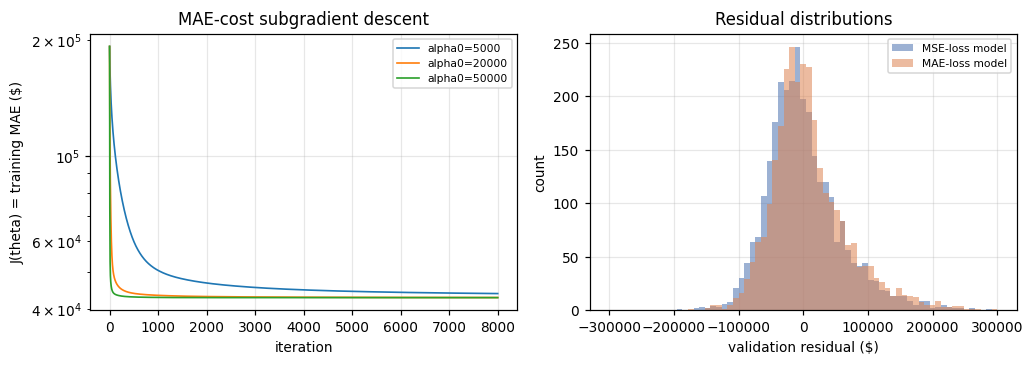

,MSE,RMSE,MAE,R2,R2_adj
validation,,,,,
"GD, MSE cost",3.469004e+09,58898.2481,43889.7412,0.6482,0.6469
"GD, MAE cost",3.616139e+09,60134.3440,43261.5755,0.6333,0.6319


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for lr in MAE_LRS:
    ax[0].plot(mae_runs[lr]["hist"], lw=1.1, label=f"alpha0={lr:g}")
ax[0].set_yscale("log"); ax[0].set_xlabel("iteration")
ax[0].set_ylabel("J(theta) = training MAE ($)")
ax[0].set_title("MAE-cost subgradient descent"); ax[0].legend(fontsize=7)
bins = np.linspace(-3e5, 3e5, 70)
ax[1].hist(yva - predict(Xva, theta_gd),  bins=bins, alpha=.55, label="MSE-loss model", color="#4c72b0")
ax[1].hist(yva - predict(Xva, theta_mae), bins=bins, alpha=.55, label="MAE-loss model", color="#dd8452")
ax[1].set_xlabel("validation residual ($)"); ax[1].set_ylabel("count")
ax[1].set_title("Residual distributions"); ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

comp = table({"GD, MSE cost": mae_runs[best_mae_lr] and metrics(yva, predict(Xva, theta_gd), p),
              "GD, MAE cost": metrics(yva, predict(Xva, theta_mae), p)}, "validation")
display(comp.round(4))

**Trade-off.** Each estimator wins on the loss it was trained on: the MAE model has the lower
validation **MAE**, the MSE model the lower validation **MSE / RMSE / R²**. Squaring the
residual makes the MSE fit pay quadratically for the few very expensive districts, so it
tilts the whole hyperplane to reduce those large errors; the MAE fit weights every dollar of
error equally, giving an estimate closer to a conditional **median**, which is more robust to
outliers and heavy tails but ignores how badly it misses on the extremes. Choose MAE when
large errors are not disproportionately costly or the data are contaminated; choose MSE when
they are, or when you want the closed-form/differentiable convenience.

## 2.5 Test-set comparison

In [22]:
test_a = pd.DataFrame({
    "closed-form MMSE": {"training time (ms)": t_mmse * 1e3, **metrics(yte, predict(Xte, theta_mmse), p)},
    f"gradient descent (alpha={best_lr})": {"training time (ms)": t_gd * 1e3,
                                            **metrics(yte, predict(Xte, theta_gd), p)}}).T
test_a["||theta1-theta2||_2 (no intercept)"] = np.linalg.norm(theta_mmse[1:] - theta_gd[1:])
display(test_a.round(4))

better = "MMSE" if test_a.loc["closed-form MMSE", "MSE"] <= test_a["MSE"].iloc[1] else "GD"
theta_b = theta_mmse if better == "MMSE" else theta_gd
print("better test MSE:", better)

,training time (ms),MSE,RMSE,MAE,R2,R2_adj,||theta1-theta2||_2 (no intercept)
closed-form MMSE,8.0596,3.610566e+09,60087.9845,44411.1857,0.6067,0.6052,141.4443
gradient descent (alpha=0.1),406.0579,3.610623e+09,60088.4568,44410.9942,0.6067,0.6052,141.4443


better test MSE: MMSE


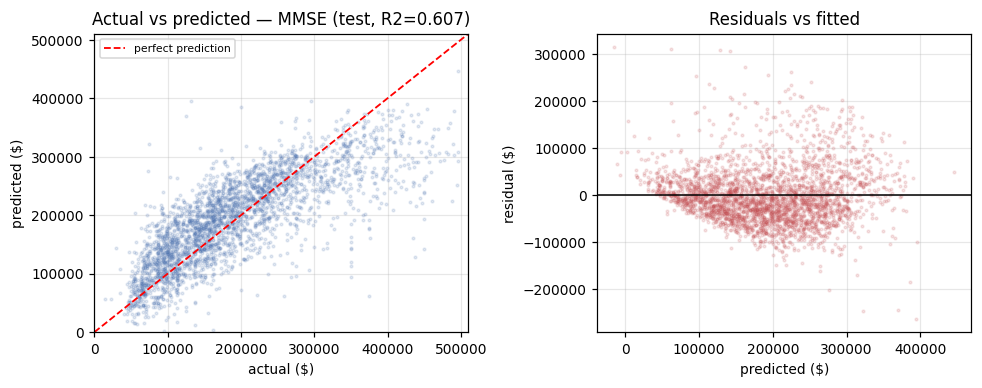

In [23]:
yh = predict(Xte, theta_b)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].scatter(yte, yh, s=3, alpha=.15, color="#4c72b0")
lim = [0, 5.1e5]; ax[0].plot(lim, lim, "r--", lw=1.2, label="perfect prediction")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("actual ($)"); ax[0].set_ylabel("predicted ($)")
ax[0].set_title(f"Actual vs predicted — {better} (test, R2={metrics(yte, yh, p)['R2']:.3f})")
ax[0].legend(fontsize=7)
ax[1].scatter(yh, yte - yh, s=3, alpha=.15, color="#c44e52")
ax[1].axhline(0, color="k", lw=1)
ax[1].set_xlabel("predicted ($)"); ax[1].set_ylabel("residual ($)")
ax[1].set_title("Residuals vs fitted")
fig.tight_layout(); plt.show()

---
# 3. Part (b) — Linear Regression vs. Ridge vs. Lasso

## 3.1 Correlation structure and conditioning

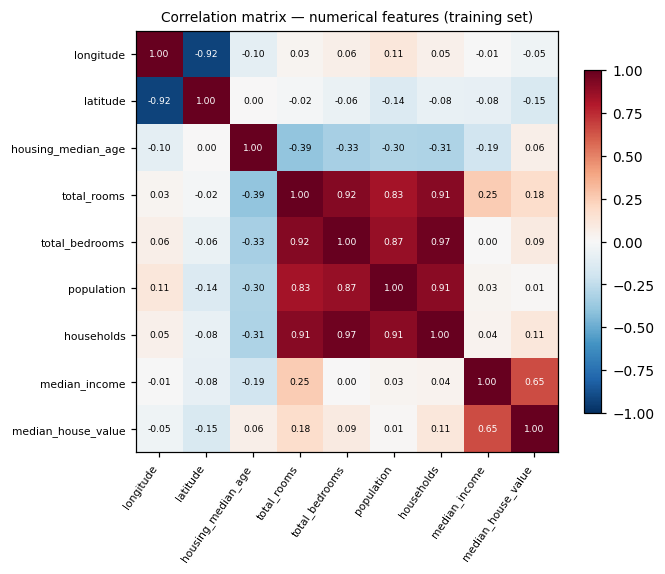

feature pairs with |r| > 0.7:
     total_bedrooms — households       r = +0.972
          longitude — latitude         r = -0.924
        total_rooms — total_bedrooms   r = +0.918
        total_rooms — households       r = +0.913
         population — households       r = +0.906
     total_bedrooms — population       r = +0.869
        total_rooms — population       r = +0.834


In [24]:
corr = train[NUM + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=55, ha="right", fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > .6 else "black")
ax.grid(False); fig.colorbar(im, shrink=.8)
ax.set_title("Correlation matrix — numerical features (training set)", fontsize=9)
fig.tight_layout(); plt.show()

cm, pairs = corr.drop(index=[TARGET], columns=[TARGET]), []
for i in range(len(cm)):
    for j in range(i + 1, len(cm)):
        if abs(cm.values[i, j]) > 0.7:
            pairs.append((cm.index[i], cm.columns[j], round(float(cm.values[i, j]), 3)))
print("feature pairs with |r| > 0.7:")
for a_, b_, r_ in sorted(pairs, key=lambda z: -abs(z[2])): print(f"   {a_:>16s} — {b_:<16s} r = {r_:+.3f}")

In [25]:
# Variance Inflation Factors: VIF_j = 1 / (1 - R^2_j) from regressing feature j on the rest
Z, vif = Xtr_s[:, :len(NUM)], {}
for k, c in enumerate(NUM):
    others = add_intercept(np.delete(Z, k, axis=1))
    b  = np.linalg.pinv(others) @ Z[:, k]
    r2 = 1 - np.sum((Z[:, k] - others @ b) ** 2) / np.sum((Z[:, k] - Z[:, k].mean()) ** 2)
    vif[c] = 1 / (1 - r2)
display(pd.Series(vif, name="VIF").sort_values(ascending=False).round(2).to_frame())

SIZE4 = ["total_rooms", "total_bedrooms", "population", "households"]
keep  = [i for i, f in enumerate(FEATS) if f not in SIZE4[1:]]
print(f"cond(X) full model                       = {np.linalg.cond(Xtr):.2f}")
print(f"cond(X) keeping only one size feature    = {np.linalg.cond(add_intercept(Xtr_s[:, keep])):.2f}")
print(f"singular values of X: {np.round(np.linalg.svd(Xtr, compute_uv=False), 1)}")

,VIF
households,27.34
total_bedrooms,24.68
total_rooms,12.78
latitude,9.30
longitude,8.96
population,5.94
median_income,2.03
housing_median_age,1.33


cond(X) full model                       = 14.01
cond(X) keeping only one size feature    = 9.34
singular values of X: [231.6 163.5 126.5 124.3 105.2  55.4  46.8  36.8  27.2  24.9  18.2  16.5]


,total_rooms,total_bedrooms,population,households
full model,-18511.0,33887.0,-43223.0,32706.0
without total_rooms,NaN,22478.0,-45087.0,28654.0
without total_bedrooms,-7541.0,NaN,-46003.0,58014.0
without population,-27898.0,48445.0,NaN,-11579.0
without households,-15077.0,56188.0,-35769.0,NaN


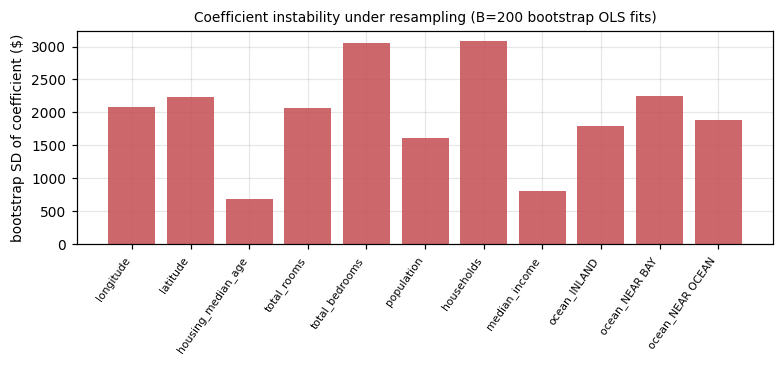

In [26]:
# Symptom 1 — coefficients swing wildly (and change sign) when a partner is removed
rows = {"full model": {f: theta_mmse[1 + FEATS.index(f)] for f in SIZE4}}
for d in SIZE4:
    cols  = [i for i, f in enumerate(FEATS) if f != d]
    names = [FEATS[i] for i in cols]
    th    = np.linalg.pinv(add_intercept(Xtr_s[:, cols])) @ ytr
    rows[f"without {d}"] = {f: (th[1 + names.index(f)] if f in names else np.nan) for f in SIZE4}
display(pd.DataFrame(rows).T.round(0))

# Symptom 2 — large sampling variance of the collinear coefficients
B, rb, boot = 200, np.random.default_rng(7), []
for _ in range(B):
    s = rb.integers(0, len(Xtr), len(Xtr))
    boot.append(np.linalg.pinv(Xtr[s]) @ ytr[s])
boot = np.array(boot)

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.bar(np.arange(len(FEATS)), boot.std(0)[1:], color="#c44e52", alpha=.85)
ax.set_xticks(np.arange(len(FEATS))); ax.set_xticklabels(FEATS, rotation=55, ha="right", fontsize=7)
ax.set_ylabel("bootstrap SD of coefficient ($)")
ax.set_title(f"Coefficient instability under resampling (B={B} bootstrap OLS fits)", fontsize=9)
fig.tight_layout(); plt.show()

**What multicollinearity does here.** `total_rooms`, `total_bedrooms`, `population` and
`households` all measure district size and are mutually correlated at r = 0.83–0.97
(`total_bedrooms` ↔ `households` is r = 0.97); `longitude` ↔ `latitude` is r = −0.92 because
California runs diagonally. Their VIFs reach 27, i.e. the standard error of those coefficients
is $\sqrt{27}\approx 5.2\times$ larger than it would be with uncorrelated features. $X^TX$ is
therefore nearly singular in those directions: the data pin down the *sum* of the size effects
precisely but the *individual split* between them hardly at all. Consequences visible above:
signs are not interpretable (`households` is +\$32.7k in the full model but **−\$11.6k** once
`population` is dropped), and the bootstrap SD of the collinear coefficients is 3–4× that of
`median_income` (VIF ≈ 2). Prediction is barely affected — only the *interpretation* and the
*stability* of individual coefficients are.

## 3.2 Ridge regression (closed form)

$$\theta_{ridge}=(X^TX+\alpha R)^{-1}X^Ty,\qquad R=\mathrm{diag}(0,1,\dots,1)$$

The leading zero in $R$ leaves the intercept unpenalised — shrinking it would bias every
prediction toward zero rather than toward the mean.

In [27]:
ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 1e4, 1e5]
Rmat = np.eye(Xtr.shape[1]); Rmat[0, 0] = 0.0        # intercept not regularised

def ridge_fit(a):
    return np.linalg.solve(XtX + a * Rmat, Xtr.T @ ytr)

ridge, ridge_path = {}, []
for a in [0.0] + ALPHAS:
    th = ridge_fit(a)
    ridge[a] = dict(theta=th, train=metrics(ytr, predict(Xtr, th), p),
                    val=metrics(yva, predict(Xva, th), p))
    if a > 0: ridge_path.append(th[1:])
ridge_path = np.array(ridge_path)

display(pd.DataFrame([{"alpha": a, "train MSE": ridge[a]["train"]["MSE"],
                       "validation MSE": ridge[a]["val"]["MSE"],
                       "validation R2": ridge[a]["val"]["R2"],
                       "||theta||_2": np.linalg.norm(ridge[a]["theta"][1:])}
                      for a in [0.0] + ALPHAS]).set_index("alpha").round(4))

best_ridge_a = min(ALPHAS, key=lambda a: ridge[a]["val"]["MSE"])
theta_ridge  = ridge[best_ridge_a]["theta"]
print("best positive alpha by validation MSE:", best_ridge_a)

,train MSE,validation MSE,validation R2,||theta||_2
alpha,,,,
0.00,3.454132e+09,3.468964e+09,0.6482,119219.9715
0.01,3.454132e+09,3.468963e+09,0.6482,119218.9793
0.10,3.454132e+09,3.468962e+09,0.6482,119210.0519
1.00,3.454133e+09,3.468950e+09,0.6482,119121.0167
10.00,3.454215e+09,3.468902e+09,0.6482,118253.7117
100.00,3.460208e+09,3.473536e+09,0.6477,111305.0872
1000.00,3.618918e+09,3.629121e+09,0.6319,85387.5301
10000.00,5.057417e+09,5.193218e+09,0.4733,42764.7532
100000.00,8.215009e+09,8.614550e+09,0.1263,8621.6824


best positive alpha by validation MSE: 10.0


## 3.3 Lasso regression (`sklearn.linear_model.Lasso`)

$$\hat\theta_{lasso}=\arg\min_\theta \Big(\tfrac1{2n}\lVert y-X\theta\rVert_2^2+\alpha\lVert\theta\rVert_1\Big)$$

**The same numeric $\alpha$ does not mean the same strength in the two models.** The Ridge
objective above is *unnormalised* ($\lVert y-X\theta\rVert_2^2 + \alpha\theta^TR\theta$), so
its penalty competes against a data term of order $n\cdot\mathrm{Var}(y)$ with
$n = 13{,}750$; sklearn's Lasso objective is divided by $2n$, so its penalty competes against a
data term of order $\mathrm{Var}(y)/2$. Sharing the grid is deliberate — it lets us watch both
paths over the same axis — but the two curves should **not** be expected to line up at equal
$\alpha$; Lasso's effective strength at a given $\alpha$ is roughly $2n \approx 2.75\times10^4$
times larger.

In [28]:
lasso, lasso_path = {}, []
for a in ALPHAS:
    m  = Lasso(alpha=a, fit_intercept=True, max_iter=200000, tol=1e-6).fit(Xtr_s, ytr)
    th = np.concatenate([[m.intercept_], m.coef_])
    lasso[a] = dict(theta=th, train=metrics(ytr, predict(Xtr, th), p),
                    val=metrics(yva, predict(Xva, th), p), nz=int(np.sum(m.coef_ != 0)))
    lasso_path.append(m.coef_)
lasso_path = np.array(lasso_path)

display(pd.DataFrame([{"alpha": a, "train MSE": lasso[a]["train"]["MSE"],
                       "validation MSE": lasso[a]["val"]["MSE"],
                       "validation R2": lasso[a]["val"]["R2"],
                       "||theta||_2": np.linalg.norm(lasso[a]["theta"][1:]),
                       "# zero coefs": p - lasso[a]["nz"],
                       "zeroed features": ", ".join(f for f, c in zip(FEATS, lasso[a]["theta"][1:]) if c == 0)}
                      for a in ALPHAS]).set_index("alpha").round(4))

best_lasso_a = min(ALPHAS, key=lambda a: lasso[a]["val"]["MSE"])
theta_lasso  = lasso[best_lasso_a]["theta"]
zeroed = [f for f, c in zip(FEATS, theta_lasso[1:]) if c == 0]
print("best alpha by validation MSE:", best_lasso_a)
print(f"coefficients driven exactly to zero at the selected alpha: {len(zeroed)} -> {zeroed}")

,train MSE,validation MSE,validation R2,||theta||_2,# zero coefs,zeroed features
alpha,,,,,,
0.01,3.454132e+09,3.468964e+09,0.6482,119219.6402,0,
0.10,3.454132e+09,3.468963e+09,0.6482,119216.6587,0,
1.00,3.454132e+09,3.468963e+09,0.6482,119186.8446,0,
10.00,3.454144e+09,3.468966e+09,0.6482,118889.2543,0,
100.00,3.455346e+09,3.470039e+09,0.6481,115969.1840,0,
1000.00,3.544237e+09,3.553270e+09,0.6396,95144.2233,3,"total_rooms, ocean_NEAR BAY, ocean_NEAR OCEAN"
10000.00,4.633409e+09,4.719140e+09,0.5214,59887.2871,8,"longitude, latitude, total_rooms, total_bedroo..."
100000.00,9.378713e+09,9.863929e+09,-0.0004,0.0000,11,"longitude, latitude, housing_median_age, total..."


best alpha by validation MSE: 1.0
coefficients driven exactly to zero at the selected alpha: 0 -> []


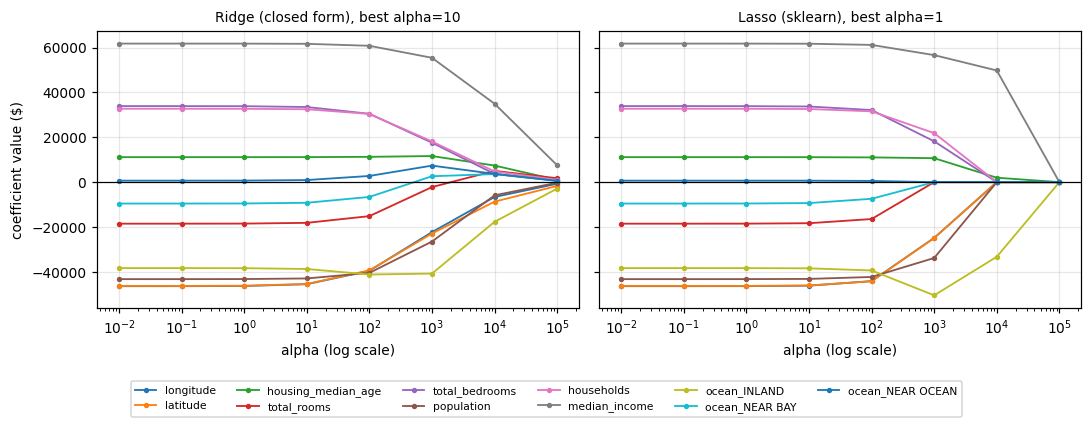

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for i, f in enumerate(FEATS):
    ax[0].plot(ALPHAS, ridge_path[:, i], lw=1.2, marker="o", ms=2.5, label=f)
    ax[1].plot(ALPHAS, lasso_path[:, i], lw=1.2, marker="o", ms=2.5, label=f)
for a_, t_ in [(ax[0], f"Ridge (closed form), best alpha={best_ridge_a:g}"),
               (ax[1], f"Lasso (sklearn), best alpha={best_lasso_a:g}")]:
    a_.set_xscale("log"); a_.set_xlabel("alpha (log scale)")
    a_.set_title(t_, fontsize=9); a_.axhline(0, color="k", lw=.8)
ax[0].set_ylabel("coefficient value ($)")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=7, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=[0, 0.10, 1, 1]); plt.show()

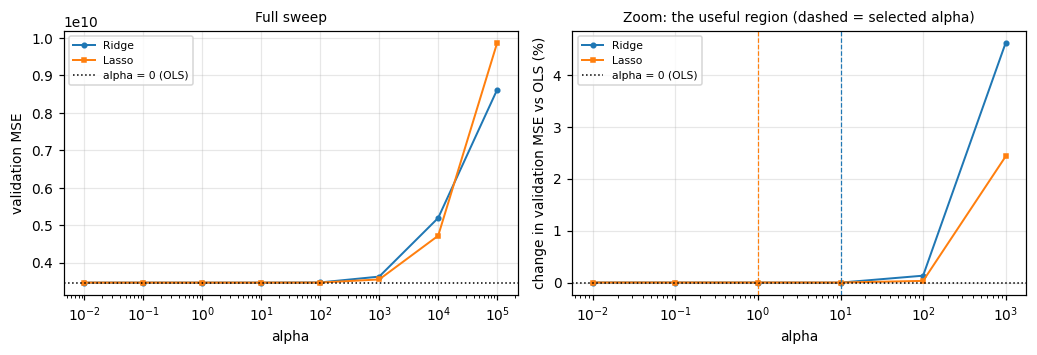

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3))
base = ridge[0.0]["val"]["MSE"]
ax[0].plot(ALPHAS, [ridge[a]["val"]["MSE"] for a in ALPHAS], "o-", label="Ridge", lw=1.3, ms=3)
ax[0].plot(ALPHAS, [lasso[a]["val"]["MSE"] for a in ALPHAS], "s-", label="Lasso", lw=1.3, ms=3)
ax[0].axhline(base, color="k", ls=":", lw=1, label="alpha = 0 (OLS)")
ax[0].set_xscale("log"); ax[0].set_xlabel("alpha"); ax[0].set_ylabel("validation MSE")
ax[0].set_title("Full sweep", fontsize=9); ax[0].legend(fontsize=7)
zoom = [a for a in ALPHAS if a <= 1000]
ax[1].plot(zoom, [1e2*(ridge[a]["val"]["MSE"]/base - 1) for a in zoom], "o-", label="Ridge", lw=1.3, ms=3)
ax[1].plot(zoom, [1e2*(lasso[a]["val"]["MSE"]/base - 1) for a in zoom], "s-", label="Lasso", lw=1.3, ms=3)
ax[1].axhline(0, color="k", ls=":", lw=1, label="alpha = 0 (OLS)")
ax[1].axvline(best_ridge_a, color="C0", ls="--", lw=.8); ax[1].axvline(best_lasso_a, color="C1", ls="--", lw=.8)
ax[1].set_xscale("log"); ax[1].set_xlabel("alpha")
ax[1].set_ylabel("change in validation MSE vs OLS (%)")
ax[1].set_title("Zoom: the useful region (dashed = selected alpha)", fontsize=9); ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

**Why Lasso can produce exact zeros and Ridge cannot.** With standardised, roughly orthogonal
columns the two penalised solutions have closed forms in terms of the OLS coefficient
$\theta_j^{OLS}$:

$$\theta_j^{ridge}=\frac{\theta_j^{OLS}}{1+\alpha}\;(\text{proportional shrinkage}),
\qquad
\theta_j^{lasso}=\operatorname{sign}(\theta_j^{OLS})\,\big(|\theta_j^{OLS}|-\alpha\big)_+\;(\text{soft-thresholding}).$$

Ridge multiplies by a factor that is never zero for finite $\alpha$; Lasso *subtracts* a
constant and truncates at zero, so any coefficient with $|\theta_j^{OLS}|\le\alpha$ becomes
exactly 0. Geometrically, the $\ell_1$ ball has corners on the axes, so the elliptical contours
of the residual sum of squares touch it at a vertex (a sparse solution) with positive
probability, whereas the $\ell_2$ ball is smooth and has no corners. Analytically, $|\theta_j|$
has a discontinuous derivative $\pm1$ at 0 that can cancel the data gradient, while
$\frac{d}{d\theta_j}\theta_j^2 = 2\theta_j$ vanishes at 0 and cannot.

**How the two paths differ (figure above).** Ridge coefficients decay smoothly and *together*,
staying non-zero even at $\alpha=10^5$ where $\lVert\theta\rVert_2$ has fallen from
119,220 to 8,622. Lasso holds coefficients nearly constant, then drops them onto zero one at a
time and they stay there — at $\alpha=10^4$, 8 of 11 are exactly zero, and at $\alpha=10^5$ all
11 are, leaving an intercept-only model (validation R² ≈ 0). The Lasso path also shows the
collinearity effect: within the size group it keeps `total_bedrooms`/`households` and discards
`total_rooms` first, because the group's shared signal can be carried by fewer columns.

## 3.4 Test-set comparison and a scarce-data check

In [31]:
def summary(th):
    m = metrics(yte, predict(Xte, th), p)
    m["||theta||_2"] = float(np.linalg.norm(th[1:]))
    m["# non-zero coefs"] = int(np.sum(th[1:] != 0))
    return m

test_b = pd.DataFrame({"Linear Regression (alpha=0)": summary(theta_mmse),
                       f"Ridge (alpha={best_ridge_a:g})": summary(theta_ridge),
                       f"Lasso (alpha={best_lasso_a:g})": summary(theta_lasso)}).T
display(test_b.round(4))

,MSE,RMSE,MAE,R2,R2_adj,||theta||_2,# non-zero coefs
Linear Regression (alpha=0),3.610566e+09,60087.9845,44411.1857,0.6067,0.6052,119219.9715,11.0
Ridge (alpha=10),3.610655e+09,60088.7272,44408.6059,0.6067,0.6052,118253.7117,11.0
Lasso (alpha=1),3.610543e+09,60087.7930,44411.0473,0.6067,0.6052,119186.8446,11.0


In [32]:
# The three models are indistinguishable because n >> p. Repeat with only 100 training rows.
small = np.random.default_rng(3).choice(len(Xtr), 100, replace=False)
Xs, ys = Xtr[small], ytr[small]
XtXs = Xs.T @ Xs

ols_s = np.linalg.pinv(Xs) @ ys
rr = {a: np.linalg.solve(XtXs + a * Rmat, Xs.T @ ys) for a in ALPHAS}
ba = min(ALPHAS, key=lambda a: metrics(yva, predict(Xva, rr[a]), p)["MSE"])
ll = {a: np.concatenate([[m.intercept_], m.coef_]) for a, m in
      ((a, Lasso(alpha=a, fit_intercept=True, max_iter=200000, tol=1e-6).fit(Xs[:, 1:], ys))
       for a in ALPHAS)}
bl = min(ALPHAS, key=lambda a: metrics(yva, predict(Xva, ll[a]), p)["MSE"])

display(pd.DataFrame({
    "OLS":                    {"validation RMSE ($)": metrics(yva, predict(Xva, ols_s), p)["RMSE"],
                               "alpha": 0, "# non-zero": int(np.sum(ols_s[1:] != 0))},
    f"Ridge": {"validation RMSE ($)": metrics(yva, predict(Xva, rr[ba]), p)["RMSE"],
               "alpha": ba, "# non-zero": int(np.sum(rr[ba][1:] != 0))},
    f"Lasso": {"validation RMSE ($)": metrics(yva, predict(Xva, ll[bl]), p)["RMSE"],
               "alpha": bl, "# non-zero": int(np.sum(ll[bl][1:] != 0))}}).T.round(1))
print("(trained on only 100 of the 13,750 training rows)")

,validation RMSE ($),alpha,# non-zero
OLS,62368.8,0.0,11.0
Ridge,61060.9,1.0,11.0
Lasso,61603.3,1000.0,7.0


(trained on only 100 of the 13,750 training rows)


---
# 4. Conclusions

**Part (a).** The closed-form MMSE estimate and the best gradient-descent run (α = 0.1) reach
the *same* optimum: identical test metrics to four decimals and
$\lVert\theta_1-\theta_2\rVert_2 = 141$ on coefficients whose norm is 119,220 — a relative gap
of 0.1 %. The closed form was roughly an order of magnitude faster than the 1,111 gradient
iterations (exact times in the table above are machine-dependent), so **for
a dataset of this size the closed form is clearly preferable**: it is one SVD, has no
hyperparameter, and cannot diverge (α = 0.3 did). Gradient descent is the approach that
**scales**: the normal equations need $O(np^2+p^3)$ time and an $O(p^2)$ matrix that must fit in
memory, whereas each gradient step is $O(np)$ and can be run on mini-batches streamed from
disk — and gradient descent generalises unchanged to costs with no closed form, as the MAE
variant demonstrated.

**Part (b).** With $n = 13{,}750$ and $p = 11$, regularisation has almost nothing to do:
Ridge (α = 10) improved validation MSE by only 0.0018 % and Lasso (α = 1) by 0.000025 %, and on
the test set all three models agree to within 0.003 %. That is the honest result — **prefer plain Linear
Regression when $n \gg p$, the features are not redundant and you want an unbiased estimate**.
The regularisers matter when that ratio changes: refitting on 100 training rows, OLS reaches
validation RMSE \$62,369 while Ridge reaches \$61,061 and Lasso \$61,603 with 7 of 11 features
retained.

**Prefer Ridge** when predictors are strongly correlated and you must keep them all — it
resolves the near-singular $X^TX$ by adding $\alpha$ to every eigenvalue, trading a little bias
for a large variance reduction, and it splits the shared signal smoothly across the correlated
group instead of picking arbitrarily. *Real-world example:* predicting a patient's blood
pressure from many overlapping physiological measurements (BMI, weight, waist circumference,
body-fat percentage) — each is genuinely informative, none should be discarded, and OLS
coefficients would flip sign between samples.

**Prefer Lasso** when you expect most features to be irrelevant and you want the model to say
*which* ones — it performs selection and estimation in one step and yields a model that is
cheap to deploy and possible to explain. *Real-world example:* genomic association studies with
20,000 gene-expression probes and a few hundred patients, where the goal is to isolate the
handful of genes that actually drive the response.

**Caveats.** $R^2 \approx 0.61$ on the test set means a linear model in these features explains
only ~61 % of the variance; the residual plot shows systematic under-prediction of expensive
districts, so a non-linear model or engineered ratio features (rooms per household, bedrooms
per room, population per household) would likely help. Removing the 992 censored districts also
means the model is not valid above \$500,000.